# Cross-Project Software Defect Prediction

**Reproducible experiment notebook**  
Primary model: Random Forest · Baseline: most-frequent Dummy Classifier · Validation: Leave-One-Project-Out

This notebook is a self-contained presentation and executable version of the repository's cross-project defect prediction experiment. It loads the original CSV, rebuilds the binary target, runs the fixed 39-fold protocol, calculates the agreed metrics and aggregation paths, and saves the results in a new run-specific output folder.

**Execution guide:** Run the required cells from top to bottom through the main results. Optional investigations at the end only run when their commented call is explicitly enabled.


## 1. Introduction and experiment overview

Software defect prediction uses software metrics to estimate whether a software class is defective. Cross-project defect prediction (CPDP) asks whether a model trained on several projects can predict defect labels in a project it has never seen during training.

The source CSV contains observations from multiple projects and versions. Each row represents a software class observation. The label is derived as <code>buggy = bugs &gt; 0</code>. The experiment evaluates Random Forest against a majority-class Dummy baseline.

The workflow below shows the complete primary experiment.

<pre>
Original CSV
    ↓
Validate columns and bug counts; create buggy target
    ↓
Select the approved 18 metrics and Project/Version/Class metadata
    ↓
Create one Leave-One-Project-Out fold per project (39 folds)
    ↓
For each fold: fit median imputer on training projects only
    ↓
Train Random Forest and most-frequent Dummy; predict held-out project
    ↓
Calculate Project-Version metrics
    ├── Project Summary: equal mean of version metrics within each project
    └── Project Pooled: calculate metrics from all raw predictions in each project
    ↓
Equal-project macro averages for each aggregation path
    ↓
Tables, visualizations, workbook, predictions, and run metadata
</pre>

The two project-level paths answer different questions. The project summary gives each version equal weight within a project. Project pooled metrics combine raw predictions across the project's versions before calculating a metric. They are reported separately throughout.


## 2. Environment and configuration

### Required packages

Use Python 3.12 or later. In a local clone, install the repository dependencies and a Jupyter kernel:

<pre>
uv sync
uv pip install jupyterlab ipykernel
uv run python -m ipykernel install --user --name defect-prediction
</pre>

In Google Colab, the packages below are normally available. If an import fails, run this in a separate Colab cell:

<pre>
%pip install -q pandas numpy scikit-learn matplotlib seaborn openpyxl joblib
</pre>

The first Python cell below is required. Run all required cells in order. Optional analysis functions later in the notebook are defined for reuse but do not execute their analyses unless their call cell is explicitly enabled.


In [1]:
from __future__ import annotations

import hashlib
import json
import os
import random
import re
import time
import uuid
from datetime import datetime
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    f1_score,
    matthews_corrcoef,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import LeaveOneGroupOut

try:
    from IPython.display import display
except ImportError:
    def display(value):
        pass

# Reproducibility and the experiment configuration from src/config.py
RANDOM_SEED = 42
random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)

FEATURES = [
    "noc", "cbo", "rfc", "lcom", "ca", "ce", "npm", "lcom3", "loc",
    "dam", "moa", "mfa", "cam", "ic", "cbm", "amc", "nr", "ndc",
]
EXCLUDED_FEATURES = ["nml", "isOld", "ndpv", "ner", "max(cc)", "avg(cc)"]
METADATA_COLUMNS = ["Project", "Version", "Class"]
BUG_COUNT_COLUMN = "bugs"
TARGET_COLUMN = "buggy"

N_ESTIMATORS = 200
MAX_FEATURES = "sqrt"
CLASS_WEIGHT = None
N_JOBS = -1
EXPECTED_PROJECTS = 39
ZERO_DIVISION = 0

# Optional environment overrides are useful for execution services and Colab.
DATASET_PATH_OVERRIDE = os.environ.get("SDP_DATASET_PATH") or None
OUTPUT_ROOT_OVERRIDE = os.environ.get("SDP_OUTPUT_ROOT") or None

sns.set_theme(style="whitegrid", context="notebook", palette="colorblind")
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 160, "axes.titleweight": "bold"})

print(f"Python: {os.sys.version.split()[0]}")
print(f"pandas {pd.__version__} · NumPy {np.__version__} · scikit-learn {sklearn.__version__}")
print(f"Approved predictors: {len(FEATURES)}")
print(f"Random Forest: n_estimators={N_ESTIMATORS}, max_features={MAX_FEATURES!r}, "
      f"class_weight={CLASS_WEIGHT}, random_state={RANDOM_SEED}, n_jobs={N_JOBS}")

Python: 3.12.8
pandas 3.1.1 · NumPy 2.5.4 · scikit-learn 1.9.1
Approved predictors: 18
Random Forest: n_estimators=200, max_features='sqrt', class_weight=None, random_state=42, n_jobs=-1


### Dataset and output paths

**Local Jupyter:** the notebook searches the current folder and its parents for <code>resources/ds.csv</code>. If the notebook server starts in the repository root, the standard project path is used.

**Google Colab:** if no local dataset is found, the default is to upload <code>ds.csv</code>. To use Google Drive instead, change <code>DATASET_SOURCE</code> to <code>"drive"</code> before running the path cell, then set <code>DRIVE_DATASET_PATH</code> to the file's location after mounting Drive. No personal-machine path is embedded in the notebook.

Every execution writes to a unique output folder. Set <code>SDP_OUTPUT_ROOT</code> before starting the notebook to choose a different output location.


In [2]:
def find_project_root(start: Path) -> Path | None:
    for candidate in (start, *start.parents):
        if (candidate / "resources" / "ds.csv").is_file() and (candidate / "src" / "config.py").is_file():
            return candidate
    return None

IN_COLAB = False
try:
    import google.colab  # noqa: F401
    IN_COLAB = True
except ImportError:
    pass

PROJECT_ROOT = find_project_root(Path.cwd())
DATASET_SOURCE = "upload"  # In Colab, set to "drive" to load from Google Drive.
DRIVE_DATASET_PATH = "/content/drive/MyDrive/ds.csv"

if DATASET_PATH_OVERRIDE:
    DATASET_PATH = Path(DATASET_PATH_OVERRIDE).expanduser()
elif PROJECT_ROOT is not None:
    DATASET_PATH = PROJECT_ROOT / "resources" / "ds.csv"
elif (Path.cwd() / "resources" / "ds.csv").is_file():
    PROJECT_ROOT = Path.cwd()
    DATASET_PATH = PROJECT_ROOT / "resources" / "ds.csv"
elif (Path.cwd() / "ds.csv").is_file():
    DATASET_PATH = Path.cwd() / "ds.csv"
elif IN_COLAB:
    if DATASET_SOURCE.lower() == "drive":
        from google.colab import drive
        drive.mount("/content/drive")
        DATASET_PATH = Path(DRIVE_DATASET_PATH)
    else:
        from google.colab import files
        uploaded = files.upload()
        csv_names = [name for name in uploaded if name.lower().endswith(".csv")]
        if not csv_names:
            raise FileNotFoundError("Upload a CSV file such as ds.csv.")
        selected_name = "ds.csv" if "ds.csv" in csv_names else csv_names[0]
        DATASET_PATH = Path("/content") / selected_name
        DATASET_PATH.write_bytes(uploaded[selected_name])
else:
    raise FileNotFoundError(
        "Could not find resources/ds.csv. Put the dataset in the repository's resources/ "
        "folder or set SDP_DATASET_PATH to its location."
    )

if not DATASET_PATH.is_file():
    raise FileNotFoundError(f"Dataset not found: {DATASET_PATH}")

if OUTPUT_ROOT_OVERRIDE:
    OUTPUT_ROOT = Path(OUTPUT_ROOT_OVERRIDE).expanduser()
elif IN_COLAB:
    OUTPUT_ROOT = Path("/content/defect_prediction_outputs")
elif PROJECT_ROOT is not None:
    OUTPUT_ROOT = PROJECT_ROOT / "outputs" / "notebook_runs"
else:
    OUTPUT_ROOT = Path.cwd() / "defect_prediction_outputs"

RUN_ID = datetime.now().astimezone().strftime("notebook_run_%Y%m%d_%H%M%S") + "_" + uuid.uuid4().hex[:8]
RUN_DIR = OUTPUT_ROOT / RUN_ID
print(f"Dataset: {DATASET_PATH}")
print(f"Output folder for this execution: {RUN_DIR}")

Dataset: /Users/areen/Projects/PythonProjects/cross-project-software-defect-prediction/resources/ds.csv
Output folder for this execution: /tmp/sdp_notebook_validation_outputs/notebook_run_20261111_113645_7bf72572


## 3. Dataset loading and understanding

The loader mirrors the project's CSV handling: blanks and the hyphen placeholder become missing values, and mixed-type inference is disabled. The raw frame is retained unchanged in memory; target construction creates a separate copy.

The following tables show the dataset dimensions, column types, missingness, project/version coverage, class balance, project sizes, and descriptive statistics for the approved predictors.


In [3]:
if DATASET_PATH.stat().st_size == 0:
    raise ValueError(f"Dataset is an empty file: {DATASET_PATH}")

raw_df = pd.read_csv(DATASET_PATH, low_memory=False, na_values=["-"])
if raw_df.empty:
    raise ValueError("Dataset contains no observations.")
if raw_df.columns.duplicated().any():
    raise ValueError(f"Duplicate column names: {raw_df.columns[raw_df.columns.duplicated()].tolist()}")

print(f"Dataset shape: {raw_df.shape[0]:,} rows × {raw_df.shape[1]} columns")
print(f"File size: {DATASET_PATH.stat().st_size / (1024 * 1024):.2f} MiB")
display(pd.DataFrame({"Column": raw_df.columns, "Data type": raw_df.dtypes.astype(str).values})
        .set_index("Column").T)
display(raw_df.dtypes.rename("Data type").to_frame())


Dataset shape: 110,917 rows × 29 columns
File size: 11.62 MiB


Column,Unnamed: 0,Project,Version,Class,noc,cbo,rfc,lcom,ca,ce,npm,lcom3,loc,dam,moa,mfa,cam,ic,cbm,amc,nr,ndc,nml,isOld,ndpv,ner,max(cc),avg(cc),bugs
Data type,int64,str,str,str,int64,int64,float64,int64,int64,int64,int64,float64,int64,float64,int64,float64,int64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,int64


,Data type
Unnamed: 0,int64
Project,str
Version,str
Class,str
noc,int64
cbo,int64
rfc,float64
lcom,int64
ca,int64
ce,int64


In [4]:
all_missing = raw_df.isna().sum().rename("Missing_Count").to_frame()
all_missing["Missing_Percent"] = 100 * all_missing["Missing_Count"] / len(raw_df)
display(all_missing.sort_values("Missing_Percent", ascending=False).round(2))

project_count = raw_df["Project"].nunique(dropna=True)
version_count = raw_df["Version"].nunique(dropna=True)
project_version_count = raw_df.groupby(["Project", "Version"], dropna=False).ngroups
missing_versions = int(raw_df["Version"].isna().sum())

project_sizes = raw_df.groupby("Project", dropna=False).size().rename("Observations")
print(f"Projects: {project_count} | distinct non-missing version labels: {version_count} | "
      f"project-version groups (including missing Version): {project_version_count}")
print(f"Rows with Version missing: {missing_versions:,}")
display(project_sizes.describe().to_frame().T)
display(project_sizes.sort_values(ascending=False).rename_axis("Project").to_frame().head(12))


Projects: 39 | distinct non-missing version labels: 75 | project-version groups (including missing Version): 93
Rows with Version missing: 6,369


,Missing_Count,Missing_Percent
avg(cc),104880,94.56
ner,35492,32.00
ndpv,34690,31.28
nml,32947,29.70
max(cc),26773,24.14
isOld,24125,21.75
Version,6369,5.74
lcom3,1162,1.05
rfc,303,0.27
nr,62,0.06


,count,mean,std,min,25%,50%,75%,max
Observations,39.0,2844.025641,5516.920596,10.0,64.5,245.0,2189.5,23058.0


,Observations
Project,
prop-1,23058
prop-5,20406
prop-2,13159
prop-43,11679
prop-3,8867
prop-4,8573
xalan,4171
jEdit,3695
camel,3575


### Target distribution and predictor summaries

The target is created only after validating its source column. The class table includes counts and proportions; the predictor summary is descriptive and does not fit any model or preprocessing.


In [5]:
required_columns = set(FEATURES + METADATA_COLUMNS + [BUG_COUNT_COLUMN])
missing_required = sorted(required_columns - set(raw_df.columns))
if missing_required:
    raise ValueError(f"Required columns are missing: {missing_required}")

bug_counts = pd.to_numeric(raw_df[BUG_COUNT_COLUMN], errors="coerce")
if bug_counts.isna().any():
    raise ValueError("The bugs column contains missing or non-numeric values.")
if not np.isfinite(bug_counts.to_numpy(dtype=float)).all():
    raise ValueError("The bugs column contains infinite values.")
if (bug_counts < 0).any():
    raise ValueError("The bugs column contains negative values.")

df = raw_df.copy()
df[TARGET_COLUMN] = bug_counts > 0
class_distribution = (
    df[TARGET_COLUMN].value_counts().reindex([False, True], fill_value=0)
    .rename(index={False: "Non-buggy", True: "Buggy"})
    .rename("Observations").to_frame()
)
class_distribution["Percent"] = 100 * class_distribution["Observations"] / len(df)
display(class_distribution.round(2))

print("Approved predictor descriptive statistics:")
display(df[FEATURES].describe().T.round(3))
print(f"Buggy observations: {int(df[TARGET_COLUMN].sum()):,} "
      f"({df[TARGET_COLUMN].mean():.2%})")
print(f"Non-buggy observations: {int((~df[TARGET_COLUMN]).sum()):,} "
      f"({(~df[TARGET_COLUMN]).mean():.2%})")

Approved predictor descriptive statistics:
Buggy observations: 102,167 (92.11%)
Non-buggy observations: 8,750 (7.89%)


,Observations,Percent
buggy,,
Non-buggy,8750,7.89
Buggy,102167,92.11


,count,mean,std,min,25%,50%,75%,max
noc,110917.0,5.757,9.592,0.0,2.000,3.000,6.000,413.0
cbo,110917.0,2.776,1.673,0.0,1.000,3.000,4.000,9.0
rfc,110614.0,0.536,7.648,0.0,0.000,0.000,0.000,546.0
lcom,110917.0,13.444,19.181,0.0,4.000,10.000,17.000,860.0
ca,110917.0,23.493,27.486,0.0,8.000,16.000,28.000,583.0
ce,110917.0,42.550,605.543,0.0,1.000,2.000,8.000,59977.0
npm,110917.0,3.024,16.104,0.0,0.000,1.000,2.000,860.0
lcom3,109755.0,10.403,10.054,0.0,3.000,8.000,15.000,133.0
loc,110917.0,3.944,8.153,0.0,1.000,2.000,3.000,347.0
dam,110917.0,1.269,0.622,0.0,0.874,1.000,2.000,2.0


## 4. Data preparation and feature selection

The target is <code>buggy = bugs &gt; 0</code>. The predictor matrix is selected from an explicit allow-list of 18 approved software metrics. The six excluded features are omitted following the supervisor's feature-selection decision; this decision is not evidence that each excluded feature is empty or unimportant.

<code>Project</code> defines LOPO groups; <code>Version</code> and <code>Class</code> support reporting and traceability; <code>bugs</code> creates the target. None are model predictors. The CSV's index-like column and all unexpected columns are also outside the explicit predictor list.


In [6]:
known_columns = set(FEATURES + EXCLUDED_FEATURES + METADATA_COLUMNS + [BUG_COUNT_COLUMN, TARGET_COLUMN])
unexpected_columns = [column for column in raw_df.columns if column not in known_columns]
print("Excluded features:", ", ".join(EXCLUDED_FEATURES))
print("Metadata / target-source fields excluded from X:", ", ".join(METADATA_COLUMNS + [BUG_COUNT_COLUMN]))
print("Other columns not used as predictors:", ", ".join(unexpected_columns) if unexpected_columns else "None")

for feature in FEATURES:
    if not pd.api.types.is_numeric_dtype(df[feature]):
        raise ValueError(f"Predictor {feature!r} must be numeric; found {df[feature].dtype}.")
    if np.isinf(df[feature].dropna().to_numpy(dtype=float)).any():
        raise ValueError(f"Infinite values found in predictor {feature!r}.")

X = df.loc[:, FEATURES].copy()
y = df.loc[:, TARGET_COLUMN].astype(bool).copy()
metadata = df.loc[:, METADATA_COLUMNS].copy()

assert list(X.columns) == FEATURES
assert not (set(X.columns) & set(METADATA_COLUMNS + [BUG_COUNT_COLUMN, TARGET_COLUMN]))
assert metadata["Project"].notna().all()
assert y.notna().all()
assert len(X) == len(y) == len(metadata)
if metadata["Project"].nunique() != EXPECTED_PROJECTS:
    raise ValueError(
        f"The documented protocol expects {EXPECTED_PROJECTS} projects; "
        f"the loaded dataset has {metadata['Project'].nunique()}."
    )

print(f"Prepared X: {X.shape}; y: {y.shape}; metadata: {metadata.shape}")
print(f"Global missing predictor values: {int(X.isna().sum().sum()):,}")
display(X.isna().sum().rename("Missing values").to_frame().T)

Excluded features: nml, isOld, ndpv, ner, max(cc), avg(cc)
Metadata / target-source fields excluded from X: Project, Version, Class, bugs
Other columns not used as predictors: Unnamed: 0
Prepared X: (110917, 18); y: (110917,); metadata: (110917, 3)
Global missing predictor values: 1,589


,noc,cbo,rfc,lcom,ca,ce,npm,lcom3,loc,dam,moa,mfa,cam,ic,cbm,amc,nr,ndc
Missing values,0,0,303,0,0,0,0,1162,0,0,0,0,0,0,0,62,62,0


## 5. Experimental methodology

### Why Random Forest?

The repository fixes Random Forest as its primary baseline; it does not claim the settings are optimal. A forest can represent nonlinear threshold patterns and interactions among software metrics without feature scaling. This suits a first experiment where relationships may not be linear and metric ranges may differ. Trees are less affected by monotonic changes of scale than distance- or margin-based models, although extreme observations can still affect split choices. No outlier removal or scaling is added to this protocol.

The fixed settings are 200 trees, <code>max_features="sqrt"</code>, no class weighting, seed 42, and parallel tree fitting. The majority-class Dummy is a transparent reference: in each fold it predicts the most frequent training label for every test row. With an imbalanced target it can achieve high accuracy while ignoring the minority class, so accuracy is not interpreted alone.

### Why LOPO?

A random row split could place observations from the same project in both training and test sets. Leave-One-Project-Out (LOPO) holds out every row from one project, trains on the remaining projects, and repeats once per project. The expected run has 39 folds; each project is tested exactly once. This estimates transfer to an unseen project within this dataset. It is not a future-version split for a known project.

Any learned preprocessing is fitted within the training portion of each fold. The held-out project is transformed using those training-derived values only.


## 6. Fold-local preprocessing

The Random Forest does not use a scaler. Missing predictor values use median imputation fitted separately for each training fold. That same fitted imputer transforms its training rows and the held-out project's rows.

If a feature is entirely missing among the training projects, the repository's <code>SimpleImputer(strategy="median", keep_empty_features=False)</code> behavior drops it for that fold. Its values in the held-out project are not used to invent a median. The dropped feature names are saved with the fold model so this decision can be audited.


In [7]:
def impute_fold_data(X_train: pd.DataFrame, X_test: pd.DataFrame):
    if not X_train.columns.equals(X_test.columns):
        raise ValueError("Train and test feature columns must match in name and order.")

    # Determine empty columns from training rows only. This mirrors the
    # repository imputer's keep_empty_features=False behavior across versions.
    retained_columns = X_train.columns[X_train.notna().any(axis=0)].tolist()
    dropped_features = [column for column in X_train.columns if column not in retained_columns]
    if not retained_columns:
        raise ValueError("Every predictor is empty in the training fold.")

    imputer = SimpleImputer(strategy="median", keep_empty_features=False)
    train_values = imputer.fit_transform(X_train.loc[:, retained_columns])
    test_values = imputer.transform(X_test.loc[:, retained_columns])
    output_columns = imputer.get_feature_names_out().tolist()

    X_train_imputed = pd.DataFrame(train_values, columns=output_columns, index=X_train.index)
    X_test_imputed = pd.DataFrame(test_values, columns=output_columns, index=X_test.index)
    return X_train_imputed, X_test_imputed, imputer, dropped_features

print("Fold-local imputation function is ready.")
print("No imputer is fitted in this cell; it is fitted separately inside each fold.")

Fold-local imputation function is ready.
No imputer is fitted in this cell; it is fitted separately inside each fold.


## 7. Main experiment: Random Forest

The following cells generate positional train/test indices from the <code>Project</code> groups, then fit one configured Random Forest per held-out project. Progress is printed for each fold. Predictions retain the source row index, project, version, class, actual label, predicted label, model name, and fold identifier.


In [8]:
groups = metadata["Project"].to_numpy()
logo = LeaveOneGroupOut()
LOPO_SPLITS = list(logo.split(X, y, groups=groups))

assert len(LOPO_SPLITS) == EXPECTED_PROJECTS
assert len({metadata.iloc[test]["Project"].iloc[0] for _, test in LOPO_SPLITS}) == EXPECTED_PROJECTS
for train_indices, test_indices in LOPO_SPLITS:
    assert set(metadata.iloc[train_indices]["Project"]).isdisjoint(
        set(metadata.iloc[test_indices]["Project"])
    )
    assert metadata.iloc[test_indices]["Project"].nunique() == 1

print(f"Generated {len(LOPO_SPLITS)} folds; every held-out fold contains one project.")

Generated 39 folds; every held-out fold contains one project.


In [9]:
def new_random_forest() -> RandomForestClassifier:
    return RandomForestClassifier(
        n_estimators=N_ESTIMATORS,
        max_features=MAX_FEATURES,
        class_weight=CLASS_WEIGHT,
        random_state=RANDOM_SEED,
        n_jobs=N_JOBS,
    )

def prediction_frame(fold_result: dict, model_name: str) -> pd.DataFrame:
    test_meta = fold_result["metadata_test"].copy()
    test_meta["Source_Row"] = fold_result["source_rows"]
    test_meta["Actual"] = fold_result["y_test"].to_numpy(dtype=bool)
    test_meta["Predicted"] = np.asarray(fold_result["predictions"], dtype=bool)
    test_meta["Model"] = model_name
    test_meta["Fold_ID"] = fold_result["fold_id"]
    return test_meta[
        ["Project", "Version", "Class", "Source_Row", "Actual", "Predicted", "Model", "Fold_ID"]
    ]

def run_random_forest_lopo(X_data: pd.DataFrame, y_data: pd.Series,
                           metadata_data: pd.DataFrame, splits) -> list[dict]:
    fold_results = []
    started = time.perf_counter()
    for fold_number, (train_indices, test_indices) in enumerate(splits, start=1):
        held_out_project = metadata_data.iloc[test_indices]["Project"].iloc[0]
        X_train = X_data.iloc[train_indices]
        X_test = X_data.iloc[test_indices]
        y_train = y_data.iloc[train_indices]
        y_test = y_data.iloc[test_indices]
        X_train_imp, X_test_imp, imputer, dropped = impute_fold_data(X_train, X_test)

        model = new_random_forest()
        model.fit(X_train_imp, y_train)
        predictions = model.predict(X_test_imp)

        safe_project = re.sub(r"[^A-Za-z0-9._-]+", "_", str(held_out_project))
        fold_results.append({
            "held_out_project": held_out_project,
            "fold_id": f"lopo_{fold_number:02d}_{safe_project}",
            "train_indices": train_indices.copy(),
            "test_indices": test_indices.copy(),
            "source_rows": X_data.index[test_indices].to_numpy(),
            "metadata_test": metadata_data.iloc[test_indices].copy(),
            "y_test": y_test.copy(),
            "predictions": predictions,
            "model": model,
            "imputer": imputer,
            "dropped_features": dropped,
            "retained_features": list(X_train_imp.columns),
        })
        print(f"[{fold_number:02d}/{len(splits)}] held out {held_out_project}: "
              f"{len(test_indices):,} test rows; dropped empty training features: {dropped or 'none'}")
    print(f"Random Forest LOPO finished in {time.perf_counter() - started:.1f} seconds.")
    return fold_results

rf_fold_results = run_random_forest_lopo(X, y, metadata, LOPO_SPLITS)
rf_predictions = pd.concat(
    [prediction_frame(result, "Random Forest") for result in rf_fold_results],
    ignore_index=True,
)
assert len(rf_fold_results) == EXPECTED_PROJECTS
assert len(rf_predictions) == len(X)
assert rf_predictions["Source_Row"].nunique() == len(X)
assert set(rf_predictions["Actual"].unique()).issubset({False, True})
print(f"Random Forest predictions: {len(rf_predictions):,}")

[01/39] held out Tomcat: 1,162 test rows; dropped empty training features: none
[02/39] held out ant: 2,442 test rows; dropped empty training features: none
[03/39] held out camel: 3,575 test rows; dropped empty training features: none
[04/39] held out ckjm: 10 test rows; dropped empty training features: none
[05/39] held out forrest: 74 test rows; dropped empty training features: none
[06/39] held out ivy: 933 test rows; dropped empty training features: none
[07/39] held out jEdit: 3,695 test rows; dropped empty training features: none
[08/39] held out log4j: 557 test rows; dropped empty training features: none
[09/39] held out lucene: 1,205 test rows; dropped empty training features: none
[10/39] held out pBeans: 96 test rows; dropped empty training features: none
[11/39] held out poi: 1,683 test rows; dropped empty training features: none
[12/39] held out prop-1: 23,058 test rows; dropped empty training features: none
[13/39] held out prop-2: 13,159 test rows; dropped empty training

## 8. Baseline experiment: Dummy Classifier

The baseline uses <code>DummyClassifier(strategy="most_frequent")</code> on the same LOPO folds. It learns only the majority target class from each training fold and ignores predictor values. Fold-local imputation is still recorded as a diagnostic, matching the repository baseline runner; the classifier itself receives zero predictor columns.


In [10]:
def run_dummy_lopo(X_data: pd.DataFrame, y_data: pd.Series,
                   metadata_data: pd.DataFrame, splits) -> list[dict]:
    fold_results = []
    started = time.perf_counter()
    for fold_number, (train_indices, test_indices) in enumerate(splits, start=1):
        held_out_project = metadata_data.iloc[test_indices]["Project"].iloc[0]
        X_train = X_data.iloc[train_indices]
        X_test = X_data.iloc[test_indices]
        y_train = y_data.iloc[train_indices]
        y_test = y_data.iloc[test_indices]
        _, _, imputer, dropped = impute_fold_data(X_train, X_test)

        # The DummyClassifier uses labels to choose its prediction and ignores X.
        model = DummyClassifier(strategy="most_frequent")
        model.fit(X_train.iloc[:, :0], y_train)
        predictions = model.predict(X_test.iloc[:, :0])

        safe_project = re.sub(r"[^A-Za-z0-9._-]+", "_", str(held_out_project))
        fold_results.append({
            "held_out_project": held_out_project,
            "fold_id": f"lopo_{fold_number:02d}_{safe_project}",
            "train_indices": train_indices.copy(),
            "test_indices": test_indices.copy(),
            "source_rows": X_data.index[test_indices].to_numpy(),
            "metadata_test": metadata_data.iloc[test_indices].copy(),
            "y_test": y_test.copy(),
            "predictions": predictions,
            "model": model,
            "imputer": imputer,
            "dropped_features": dropped,
        })
        print(f"[{fold_number:02d}/{len(splits)}] held out {held_out_project}: "
              f"Dummy predicted {bool(model.classes_[np.argmax(model.class_prior_)])} for all test rows")
    print(f"Dummy LOPO finished in {time.perf_counter() - started:.1f} seconds.")
    return fold_results

dummy_fold_results = run_dummy_lopo(X, y, metadata, LOPO_SPLITS)
dummy_predictions = pd.concat(
    [prediction_frame(result, "Dummy (most_frequent)") for result in dummy_fold_results],
    ignore_index=True,
)
assert len(dummy_fold_results) == EXPECTED_PROJECTS
assert len(dummy_predictions) == len(X)
assert rf_predictions[["Project", "Version", "Class", "Actual"]].equals(
    dummy_predictions[["Project", "Version", "Class", "Actual"]]
)
print(f"Dummy predictions: {len(dummy_predictions):,}; observations align with Random Forest.")

[01/39] held out Tomcat: Dummy predicted True for all test rows
[02/39] held out ant: Dummy predicted True for all test rows
[03/39] held out camel: Dummy predicted True for all test rows
[04/39] held out ckjm: Dummy predicted True for all test rows
[05/39] held out forrest: Dummy predicted True for all test rows
[06/39] held out ivy: Dummy predicted True for all test rows
[07/39] held out jEdit: Dummy predicted True for all test rows
[08/39] held out log4j: Dummy predicted True for all test rows
[09/39] held out lucene: Dummy predicted True for all test rows
[10/39] held out pBeans: Dummy predicted True for all test rows
[11/39] held out poi: Dummy predicted True for all test rows
[12/39] held out prop-1: Dummy predicted True for all test rows
[13/39] held out prop-2: Dummy predicted True for all test rows
[14/39] held out prop-3: Dummy predicted True for all test rows
[15/39] held out prop-4: Dummy predicted True for all test rows
[16/39] held out prop-42: Dummy predicted True for al

## 9. Evaluation metrics

The confusion matrix uses the label order <code>[False, True]</code>: TN and FP refer to non-buggy classes; FN and TP refer to buggy classes. Accuracy measures the fraction correct. Precision measures the reliability of buggy predictions; recall measures the share of buggy classes found. F1 is the harmonic mean of precision and recall.

Matthews Correlation Coefficient (MCC) uses all four confusion-matrix cells and is informative under class imbalance when both actual and predicted groups contain both classes. Following the repository implementation, each group receives an MCC status:

- **Informative:** actual and predicted labels both contain two classes.
- **Not informative:** the actual group contains only one class.
- **Undefined:** actual labels contain both classes, but predictions contain only one class.

At the detailed level, the repository stores numerical MCC as 0 for the last two statuses while retaining the status flag. Aggregations exclude these groups from MCC means; they are never treated as ordinary zero-valued MCC results.


In [11]:
def get_mcc_status(actual, predicted) -> str:
    actual = pd.Series(actual)
    predicted = pd.Series(predicted)
    if actual.nunique() < 2:
        return "Not informative"
    if predicted.nunique() < 2:
        return "Undefined"
    return "Informative"

def metric_record(actual, predicted) -> dict:
    actual = np.asarray(actual, dtype=bool)
    predicted = np.asarray(predicted, dtype=bool)
    tn, fp, fn, tp = confusion_matrix(actual, predicted, labels=[False, True]).ravel()
    status = get_mcc_status(actual, predicted)
    mcc_value = float(matthews_corrcoef(actual, predicted)) if status == "Informative" else 0.0
    return {
        "Support": int(len(actual)),
        "Buggy_Count": int(actual.sum()),
        "Non_Buggy_Count": int((~actual).sum()),
        "Accuracy": float(accuracy_score(actual, predicted)),
        "Precision": float(precision_score(actual, predicted, zero_division=ZERO_DIVISION)),
        "Recall": float(recall_score(actual, predicted, zero_division=ZERO_DIVISION)),
        "F1": float(f1_score(actual, predicted, zero_division=ZERO_DIVISION)),
        "MCC": mcc_value,
        "MCC_Status": status,
        "TN": int(tn), "FP": int(fp), "FN": int(fn), "TP": int(tp),
    }

def evaluate_predictions(predictions: pd.DataFrame) -> pd.DataFrame:
    required = {"Project", "Version", "Actual", "Predicted"}
    missing = sorted(required - set(predictions.columns))
    if missing:
        raise ValueError(f"Prediction data is missing columns: {missing}")
    if predictions.empty or predictions[["Project", "Actual", "Predicted"]].isna().any().any():
        raise ValueError("Predictions must be non-empty and have no missing project or labels.")
    rows = []
    for (project, version), group in predictions.groupby(
        ["Project", "Version"], dropna=False, sort=False
    ):
        row = {"Project": project, "Version": version}
        row.update(metric_record(group["Actual"], group["Predicted"]))
        rows.append(row)
    return pd.DataFrame(rows)

def aggregate_project_metrics(version_metrics: pd.DataFrame) -> pd.DataFrame:
    rows = []
    for project, group in version_metrics.groupby("Project", sort=False, dropna=False):
        row = {
            "Project": project,
            "Version_Count": int(len(group)),
            "Support": int(group["Support"].sum()),
            "Buggy_Count": int(group["Buggy_Count"].sum()),
            "Non_Buggy_Count": int(group["Non_Buggy_Count"].sum()),
        }
        for metric in ["Accuracy", "Precision", "Recall", "F1"]:
            row[metric] = float(group[metric].mean())
            row[f"{metric}_Weighted"] = float(np.average(group[metric], weights=group["Support"]))
        informative_versions = group.loc[group["MCC_Status"] == "Informative", "MCC"]
        row["MCC"] = float(informative_versions.mean()) if len(informative_versions) else np.nan
        row["MCC_Informative_Versions"] = int(len(informative_versions))
        row["MCC_Status"] = "Informative" if len(informative_versions) else "No informative groups"
        for count in ["TN", "FP", "FN", "TP"]:
            row[count] = int(group[count].sum())
        rows.append(row)
    return pd.DataFrame(rows)

def calculate_project_pooled_metrics(predictions: pd.DataFrame) -> pd.DataFrame:
    rows = []
    for project, group in predictions.groupby("Project", sort=False, dropna=False):
        row = {"Project": project}
        row.update(metric_record(group["Actual"], group["Predicted"]))
        rows.append(row)
    return pd.DataFrame(rows)

def calculate_macro_average(project_metrics: pd.DataFrame, aggregation: str,
                            mcc_status_column: str | None = None) -> pd.DataFrame:
    row = {"Aggregation": aggregation, "Project_Count": int(project_metrics["Project"].nunique())}
    for metric in ["Accuracy", "Precision", "Recall", "F1"]:
        row[metric] = float(project_metrics[metric].mean())
    if mcc_status_column is None:
        informative = project_metrics["MCC_Informative_Versions"] > 0
    else:
        informative = project_metrics[mcc_status_column] == "Informative"
    row["MCC"] = float(project_metrics.loc[informative, "MCC"].mean()) if informative.any() else np.nan
    row["MCC_Informative_Projects"] = int(informative.sum())
    return pd.DataFrame([row])

print("Evaluation functions are ready. Precision, recall, and F1 use zero_division=0.")

Evaluation functions are ready. Precision, recall, and F1 use zero_division=0.


## 10. Evaluation and aggregation

Three levels are calculated separately:

**A. Project-Version:** calculate metrics for each held-out project's version group. Missing version labels remain a group and are displayed as “Version unavailable.”

**B. Project Summary:** average each version metric equally within its project, so a small version has the same weight as a large version. MCC averages informative version groups only.

**C. Project Pooled:** pool the raw predictions across a project's versions first, then calculate that project's metrics once.

The macro average of Project Summary gives every project equal weight. The separate macro average of Project Pooled also gives every project equal weight. These are not interchangeable. No dataset-wide pooled metric is added to the primary comparison.


In [12]:
model_predictions = {
    "Random Forest": rf_predictions,
    "Dummy (most_frequent)": dummy_predictions,
}
version_metrics_by_model = {}
project_summary_by_model = {}
project_pooled_by_model = {}
macro_summary_rows = []
macro_pooled_rows = []

for model_name, predictions in model_predictions.items():
    version_metrics = evaluate_predictions(predictions)
    version_metrics.insert(0, "Model", model_name)
    version_metrics["Version_Display"] = version_metrics["Version"].where(
        version_metrics["Version"].notna(), "Version unavailable"
    )
    project_summary = aggregate_project_metrics(version_metrics)
    project_summary.insert(0, "Model", model_name)
    project_pooled = calculate_project_pooled_metrics(predictions)
    project_pooled.insert(0, "Model", model_name)

    summary_macro = calculate_macro_average(
        project_summary,
        "Project Summary macro (equal project weight)",
    )
    summary_macro.insert(0, "Model", model_name)
    pooled_macro = calculate_macro_average(
        project_pooled,
        "Project Pooled macro (equal project weight)",
        mcc_status_column="MCC_Status",
    )
    pooled_macro.insert(0, "Model", model_name)

    version_metrics_by_model[model_name] = version_metrics
    project_summary_by_model[model_name] = project_summary
    project_pooled_by_model[model_name] = project_pooled
    macro_summary_rows.append(summary_macro)
    macro_pooled_rows.append(pooled_macro)

version_metrics_all = pd.concat(version_metrics_by_model.values(), ignore_index=True)
project_summary_all = pd.concat(project_summary_by_model.values(), ignore_index=True)
project_pooled_all = pd.concat(project_pooled_by_model.values(), ignore_index=True)
macro_summary_all = pd.concat(macro_summary_rows, ignore_index=True)
macro_pooled_all = pd.concat(macro_pooled_rows, ignore_index=True)
macro_averages = pd.concat([macro_summary_all, macro_pooled_all], ignore_index=True)

assert len(version_metrics_by_model["Random Forest"]) == len(version_metrics_by_model["Dummy (most_frequent)"])
assert project_summary_all.groupby("Model")["Project"].nunique().eq(EXPECTED_PROJECTS).all()
assert project_pooled_all.groupby("Model")["Project"].nunique().eq(EXPECTED_PROJECTS).all()
print(f"Project-Version groups per model: {len(version_metrics_by_model['Random Forest'])}")
print(f"Project rows per model: {EXPECTED_PROJECTS}")


Project-Version groups per model: 93
Project rows per model: 39


### Main macro results

The first table is the primary project-version-derived macro comparison. The second table is the distinct project-pooled macro comparison. MCC contributor counts are shown so non-informative groups are visible.


In [13]:
primary_macro_table = macro_summary_all[
    ["Model", "Aggregation", "Project_Count", "Accuracy", "Precision", "Recall", "F1",
     "MCC", "MCC_Informative_Projects"]
].copy()
pooled_macro_table = macro_pooled_all[
    ["Model", "Aggregation", "Project_Count", "Accuracy", "Precision", "Recall", "F1",
     "MCC", "MCC_Informative_Projects"]
].copy()
display(primary_macro_table.round(4).astype(object).where(primary_macro_table.notna(), "Not informative"))
display(pooled_macro_table.round(4).astype(object).where(pooled_macro_table.notna(), "Not informative"))
print("Project-Version metrics (first 12 rows):")
display(version_metrics_all.head(12))
print("Project Summary (first 12 rows):")
display(project_summary_all.head(12))
print("Project Pooled (first 12 rows):")
display(project_pooled_all.head(12))

Project-Version metrics (first 12 rows):
Project Summary (first 12 rows):
Project Pooled (first 12 rows):


,Model,Aggregation,Project_Count,Accuracy,Precision,Recall,F1,MCC,MCC_Informative_Projects
0,Random Forest,Project Summary macro (equal project weight),39,0.9973,0.9973,0.9997,0.9985,0.9781,37
1,Dummy (most_frequent),Project Summary macro (equal project weight),39,0.9335,0.9335,1.0,0.965,Not informative,0


,Model,Aggregation,Project_Count,Accuracy,Precision,Recall,F1,MCC,MCC_Informative_Projects
0,Random Forest,Project Pooled macro (equal project weight),39,0.9972,0.9973,0.9996,0.9985,0.9777,37
1,Dummy (most_frequent),Project Pooled macro (equal project weight),39,0.933,0.933,1.0,0.9648,Not informative,0


,Model,Project,Version,Support,Buggy_Count,Non_Buggy_Count,Accuracy,Precision,Recall,F1,MCC,MCC_Status,TN,FP,FN,TP,Version_Display
0,Random Forest,Tomcat,6.0.389418,1162,1073,89,0.991394,0.990766,1.000000,0.995362,0.937787,Informative,79,10,0,1073,6.0.389418
1,Random Forest,ant,1.3,187,182,5,1.000000,1.000000,1.000000,1.000000,1.000000,Informative,5,0,0,182,1.3
2,Random Forest,ant,1.4,265,255,10,1.000000,1.000000,1.000000,1.000000,1.000000,Informative,10,0,0,255,1.4
3,Random Forest,ant,1.5,401,388,13,1.000000,1.000000,1.000000,1.000000,1.000000,Informative,13,0,0,388,1.5
4,Random Forest,ant,1.6,523,504,19,1.000000,1.000000,1.000000,1.000000,1.000000,Informative,19,0,0,504,1.6
5,Random Forest,ant,1.7,1066,1017,49,0.999062,1.000000,0.999017,0.999508,0.989463,Informative,49,0,1,1016,1.7
6,Random Forest,camel,1,436,413,23,1.000000,1.000000,1.000000,1.000000,1.000000,Informative,23,0,0,413,1
7,Random Forest,camel,1.2,765,721,44,1.000000,1.000000,1.000000,1.000000,1.000000,Informative,44,0,0,721,1.2
8,Random Forest,camel,1.4,1122,1059,63,1.000000,1.000000,1.000000,1.000000,1.000000,Informative,63,0,0,1059,1.4
9,Random Forest,camel,1.6,1252,1180,72,1.000000,1.000000,1.000000,1.000000,1.000000,Informative,72,0,0,1180,1.6


,Model,Project,Version_Count,Support,Buggy_Count,Non_Buggy_Count,Accuracy,Accuracy_Weighted,Precision,Precision_Weighted,Recall,Recall_Weighted,F1,F1_Weighted,MCC,MCC_Informative_Versions,MCC_Status,TN,FP,FN,TP
0,Random Forest,Tomcat,1,1162,1073,89,0.991394,0.991394,0.990766,0.990766,1.000000,1.000000,0.995362,0.995362,0.937787,1,Informative,79,10,0,1073
1,Random Forest,ant,5,2442,2346,96,0.999812,0.999590,1.000000,1.000000,0.999803,0.999571,0.999902,0.999785,0.997893,5,Informative,96,0,1,2345
2,Random Forest,camel,4,3575,3373,202,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,4,Informative,202,0,0,3373
3,Random Forest,ckjm,1,10,10,0,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,NaN,0,No informative groups,0,0,0,10
4,Random Forest,forrest,3,74,72,2,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,2,Informative,2,0,0,72
5,Random Forest,ivy,3,933,893,40,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,3,Informative,40,0,0,893
6,Random Forest,jEdit,5,3695,3467,228,0.996758,0.996482,0.996745,0.996546,0.999810,0.999709,0.998275,0.998124,0.971686,5,Informative,216,12,1,3466
7,Random Forest,log4j,3,557,537,20,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,3,Informative,20,0,0,537
8,Random Forest,lucene,3,1205,1084,121,0.996724,0.996680,0.997038,0.997229,0.999317,0.999088,0.998175,0.998157,0.982008,3,Informative,118,3,1,1083
9,Random Forest,pBeans,2,96,86,10,0.992188,0.989583,1.000000,1.000000,0.991379,0.988506,0.995652,0.994203,0.958902,2,Informative,10,0,1,85


,Model,Project,Support,Buggy_Count,Non_Buggy_Count,Accuracy,Precision,Recall,F1,MCC,MCC_Status,TN,FP,FN,TP
0,Random Forest,Tomcat,1162,1073,89,0.991394,0.990766,1.000000,0.995362,0.937787,Informative,79,10,0,1073
1,Random Forest,ant,2442,2346,96,0.999590,1.000000,0.999574,0.999787,0.994620,Informative,96,0,1,2345
2,Random Forest,camel,3575,3373,202,1.000000,1.000000,1.000000,1.000000,1.000000,Informative,202,0,0,3373
3,Random Forest,ckjm,10,10,0,1.000000,1.000000,1.000000,1.000000,0.000000,Not informative,0,0,0,10
4,Random Forest,forrest,74,72,2,1.000000,1.000000,1.000000,1.000000,1.000000,Informative,2,0,0,72
5,Random Forest,ivy,933,893,40,1.000000,1.000000,1.000000,1.000000,1.000000,Informative,40,0,0,893
6,Random Forest,jEdit,3695,3467,228,0.996482,0.996550,0.999712,0.998128,0.969251,Informative,216,12,1,3466
7,Random Forest,log4j,557,537,20,1.000000,1.000000,1.000000,1.000000,1.000000,Informative,20,0,0,537
8,Random Forest,lucene,1205,1084,121,0.996680,0.997238,0.999077,0.998157,0.981532,Informative,118,3,1,1083
9,Random Forest,pBeans,96,86,10,0.989583,1.000000,0.988372,0.994152,0.947903,Informative,10,0,1,85


## 11. Main results and visualizations

The plots compare the models using the same aggregation definitions as the tables. Project-level distributions use the version-derived Project Summary path. The Dummy MCC is left unavailable when it has no informative project groups; it is not plotted as zero.


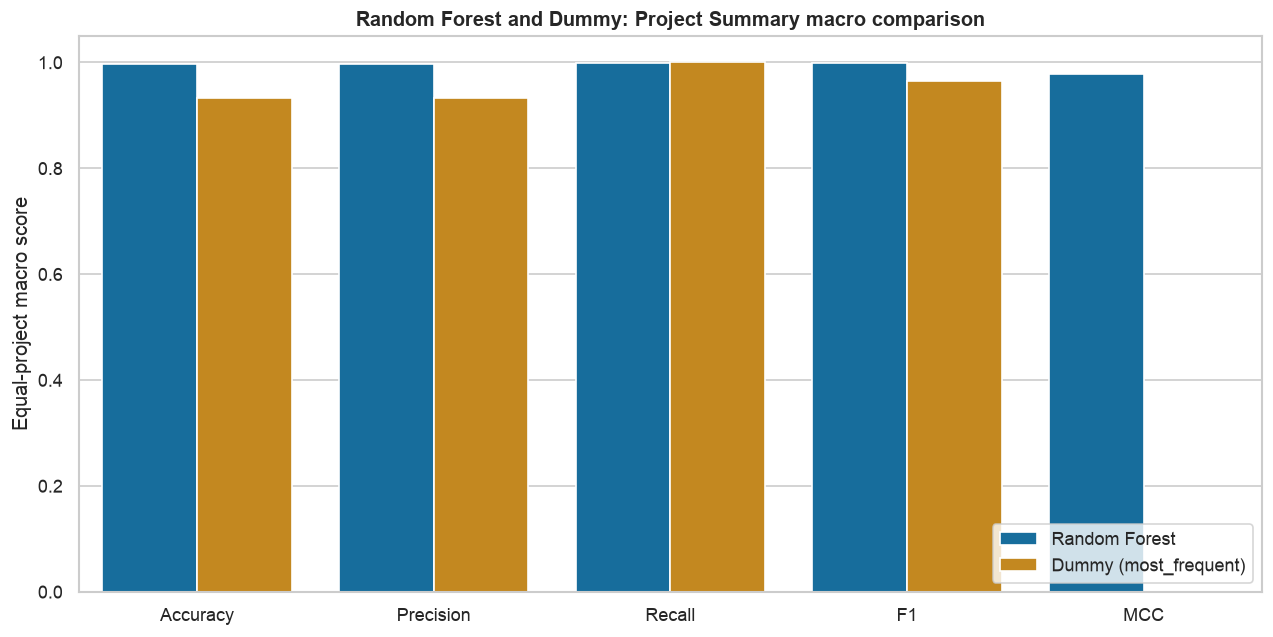

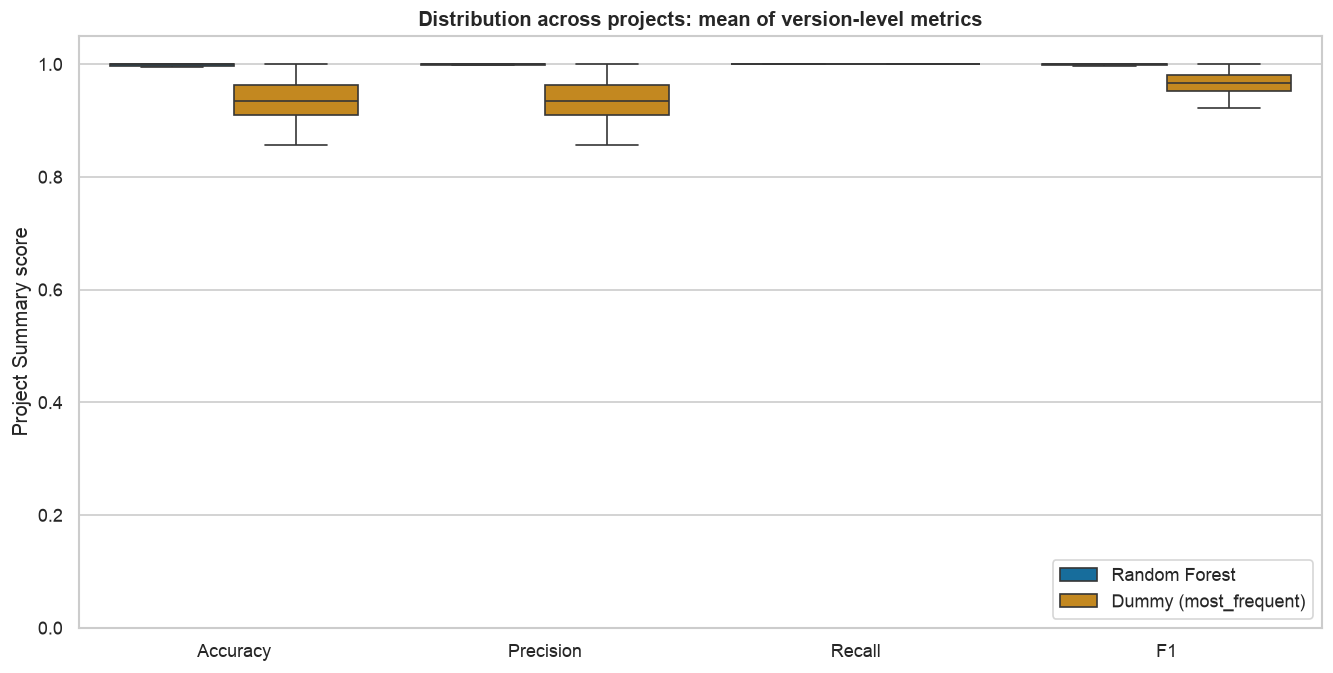

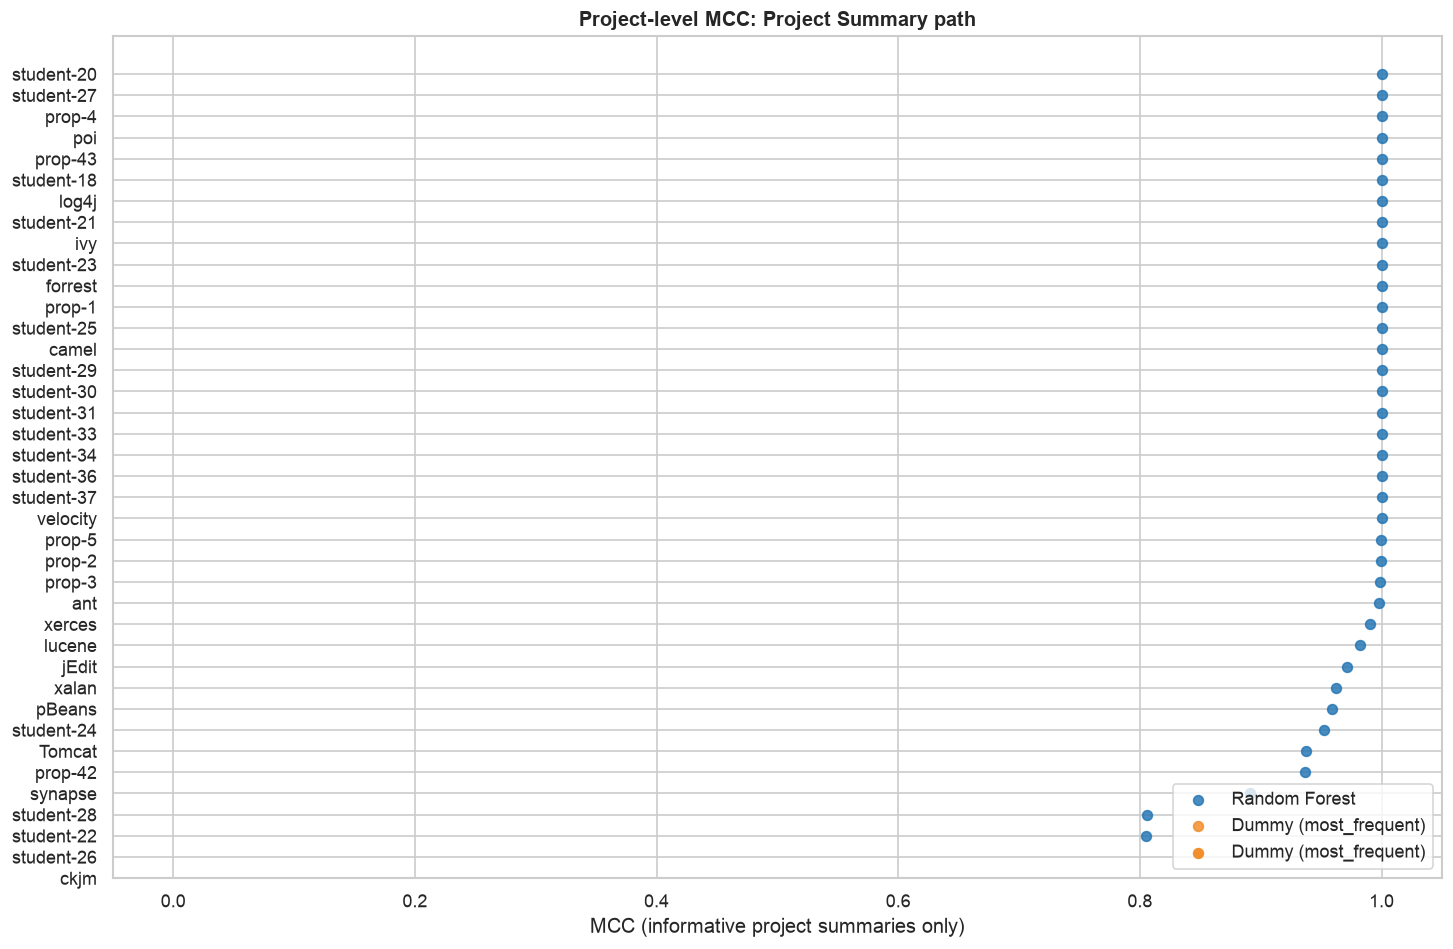

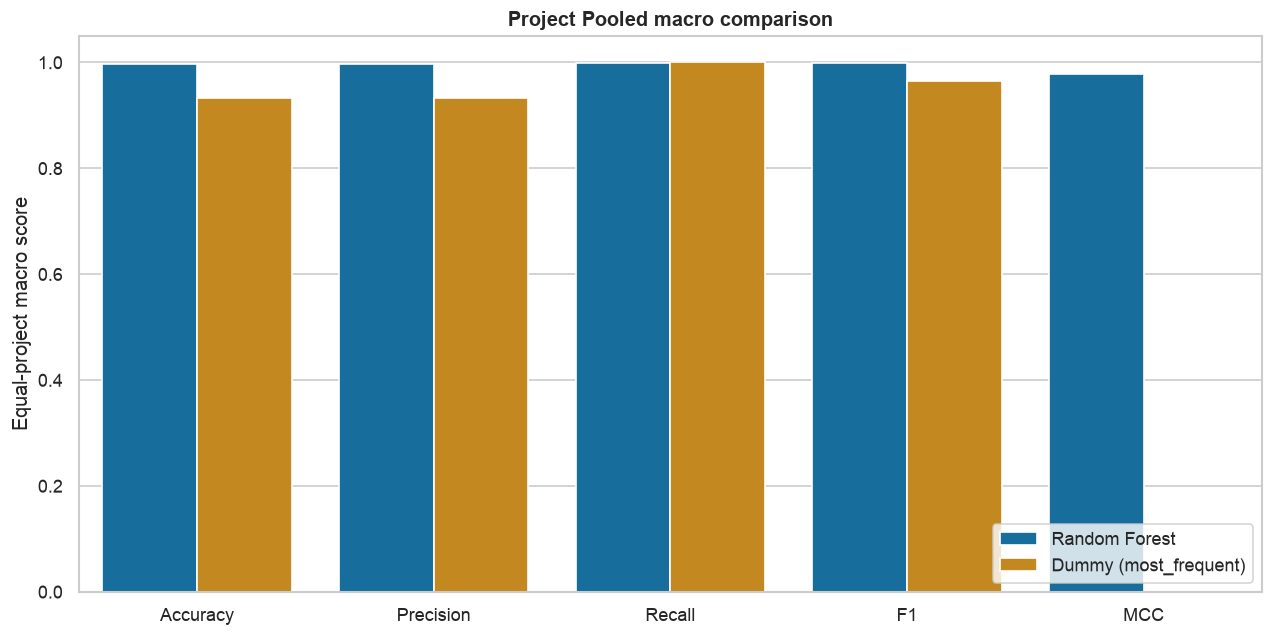

In [14]:
MAIN_FIGURES = {}

# Primary macro comparison: each bar is the equal-project average of project summaries.
primary_metrics = ["Accuracy", "Precision", "Recall", "F1", "MCC"]
primary_plot = macro_summary_all.melt(
    id_vars=["Model"], value_vars=primary_metrics, var_name="Metric", value_name="Score"
)
fig, ax = plt.subplots(figsize=(10.5, 5.2), constrained_layout=True)
sns.barplot(data=primary_plot, x="Metric", y="Score", hue="Model", ax=ax, errorbar=None)
ax.set_ylim(0, 1.05)
ax.set_ylabel("Equal-project macro score")
ax.set_xlabel("")
ax.set_title("Random Forest and Dummy: Project Summary macro comparison")
ax.legend(title="", loc="lower right")
MAIN_FIGURES["primary_macro_comparison"] = fig
plt.show()

# Project-level distribution of version-derived summary scores.
distribution_metrics = ["Accuracy", "Precision", "Recall", "F1"]
distribution_long = project_summary_all.melt(
    id_vars=["Model", "Project"], value_vars=distribution_metrics,
    var_name="Metric", value_name="Score"
)
fig, ax = plt.subplots(figsize=(11, 5.5), constrained_layout=True)
sns.boxplot(data=distribution_long, x="Metric", y="Score", hue="Model", ax=ax, showfliers=False)
ax.set_ylim(0, 1.05)
ax.set_ylabel("Project Summary score")
ax.set_xlabel("")
ax.set_title("Distribution across projects: mean of version-level metrics")
ax.legend(title="", loc="lower right")
MAIN_FIGURES["project_metric_distributions"] = fig
plt.show()

# Project-level MCC values on the primary aggregation path.
fig, ax = plt.subplots(figsize=(12, max(5.5, EXPECTED_PROJECTS * 0.20)), constrained_layout=True)
rf_projects = project_summary_all[project_summary_all["Model"] == "Random Forest"]
project_order = rf_projects.sort_values("MCC", na_position="first")["Project"].tolist()
y_position = {project: position for position, project in enumerate(project_order)}
model_colors = {"Random Forest": "#2878B5", "Dummy (most_frequent)": "#F28E2B"}
for model_name in ["Random Forest", "Dummy (most_frequent)"]:
    subset = project_summary_all[
        (project_summary_all["Model"] == model_name)
        & project_summary_all["MCC"].notna()
    ]
    y_values = [y_position[project] for project in subset["Project"]]
    ax.scatter(subset["MCC"], y_values, label=model_name,
               color=model_colors[model_name], s=34, alpha=0.85)
    if subset.empty:
        ax.scatter([], [], label=model_name, color=model_colors[model_name], s=34)
ax.set_yticks(range(len(project_order)), [str(project) for project in project_order])
ax.set_xlim(-0.05, 1.05)
ax.set_xlabel("MCC (informative project summaries only)")
ax.set_ylabel("")
ax.set_title("Project-level MCC: Project Summary path")
ax.legend(title="", loc="lower right")
MAIN_FIGURES["project_mcc"] = fig
plt.show()

# Separate project-pooled macro view to preserve the second aggregation path.
pooled_plot = macro_pooled_all.melt(
    id_vars=["Model"], value_vars=primary_metrics, var_name="Metric", value_name="Score"
)
fig, ax = plt.subplots(figsize=(10.5, 5.2), constrained_layout=True)
sns.barplot(data=pooled_plot, x="Metric", y="Score", hue="Model", ax=ax, errorbar=None)
ax.set_ylim(0, 1.05)
ax.set_ylabel("Equal-project macro score")
ax.set_xlabel("")
ax.set_title("Project Pooled macro comparison")
ax.legend(title="", loc="lower right")
MAIN_FIGURES["pooled_macro_comparison"] = fig
plt.show()

## 12. Saving results

The next cell creates a fresh run directory and saves the two prediction files, all three metric levels, both macro-average tables, an Excel workbook, the main figures, fold-specific Random Forest bundles, a separate all-data Random Forest bundle, and JSON run metadata.

The all-data model follows the documented deployment-artifact protocol. It is trained after cross-project predictions are complete; it is not evaluated here and its training performance is not part of the results.


In [15]:
RUN_DIR.mkdir(parents=True, exist_ok=False)
(RUN_DIR / "dummy_baseline").mkdir()
(RUN_DIR / "models").mkdir()
(RUN_DIR / "figures" / "main_results").mkdir(parents=True)

rf_predictions.to_csv(RUN_DIR / "predictions.csv", index=False)
dummy_predictions.to_csv(RUN_DIR / "dummy_baseline" / "predictions.csv", index=False)
version_metrics_all.to_csv(RUN_DIR / "version_metrics.csv", index=False)
project_summary_all.to_csv(RUN_DIR / "project_summary_metrics.csv", index=False)
project_pooled_all.to_csv(RUN_DIR / "project_pooled_metrics.csv", index=False)
macro_averages.to_csv(RUN_DIR / "macro_average_metrics.csv", index=False)

# Evaluation workbook with separate sheets for each level and aggregation path.
project_pooled_workbook = project_pooled_all.copy()
project_pooled_workbook["Evaluation_Level"] = "Project pooled"
pooled_macro_workbook = macro_pooled_all.copy()
pooled_macro_workbook["Evaluation_Level"] = "Project-pooled macro average"
pooled_macro_workbook["Project"] = None
pooled_macro_workbook["Support"] = None
project_pooled_workbook = pd.concat(
    [project_pooled_workbook, pooled_macro_workbook], ignore_index=True, sort=False
)

model_comparison_rows = []
for _, row in project_summary_all.iterrows():
    for metric in ["Accuracy", "Precision", "Recall", "F1", "MCC"]:
        model_comparison_rows.append({
            "Model": row["Model"], "Evaluation_Level": "Project Summary",
            "Project": row["Project"], "Metric": metric, "Value": row[metric],
        })
for _, row in macro_summary_all.iterrows():
    for metric in ["Accuracy", "Precision", "Recall", "F1", "MCC"]:
        model_comparison_rows.append({
            "Model": row["Model"], "Evaluation_Level": row["Aggregation"],
            "Project": None, "Metric": metric, "Value": row[metric],
        })
for _, row in macro_pooled_all.iterrows():
    for metric in ["Accuracy", "Precision", "Recall", "F1", "MCC"]:
        model_comparison_rows.append({
            "Model": row["Model"], "Evaluation_Level": row["Aggregation"],
            "Project": None, "Metric": metric, "Value": row[metric],
        })
model_comparison = pd.DataFrame(model_comparison_rows)

run_timestamp = datetime.now().astimezone().isoformat()
dataset_sha256 = hashlib.sha256(DATASET_PATH.read_bytes()).hexdigest()
dropped_by_project = {
    str(result["held_out_project"]): result["dropped_features"]
    for result in rf_fold_results
}
metadata_json = {
    "experiment": {
        "name": "Leave-One-Project-Out software defect prediction",
        "timestamp": run_timestamp,
        "dataset": DATASET_PATH.name,
        "dataset_sha256": dataset_sha256,
        "number_of_observations": int(len(X)),
        "number_of_projects": int(metadata["Project"].nunique()),
        "number_of_versions": int(metadata["Version"].nunique()),
        "project_version_groups_including_missing": int(
            metadata.groupby(["Project", "Version"], dropna=False).ngroups
        ),
        "number_of_folds": int(len(rf_fold_results)),
        "number_of_predictions": int(len(rf_predictions)),
        "output_run_id": RUN_ID,
        "environment": {
            "python": os.sys.version.split()[0],
            "pandas": pd.__version__,
            "numpy": np.__version__,
            "scikit_learn": sklearn.__version__,
            "matplotlib": plt.matplotlib.__version__,
            "seaborn": sns.__version__,
            "openpyxl": __import__("openpyxl").__version__,
        },
    },
    "target": {"column": TARGET_COLUMN, "definition": "buggy = bugs > 0"},
    "features": {
        "number_of_features": len(FEATURES),
        "predictors": FEATURES,
        "excluded_features": EXCLUDED_FEATURES,
    },
    "metadata_columns": METADATA_COLUMNS,
    "models": {
        "random_forest": {
            "name": "RandomForestClassifier",
            "n_estimators": N_ESTIMATORS,
            "max_features": MAX_FEATURES,
            "class_weight": CLASS_WEIGHT,
            "random_state": RANDOM_SEED,
            "n_jobs": N_JOBS,
        },
        "dummy": {"name": "DummyClassifier", "strategy": "most_frequent"},
    },
    "preprocessing": {
        "imputation_strategy": "median",
        "fit_scope": "Training rows in each outer fold only",
        "scaling": "None for the tree-based primary model",
        "dropped_features_by_held_out_project": dropped_by_project,
    },
    "evaluation": {
        "split": "LeaveOneGroupOut using Project",
        "folds": int(len(LOPO_SPLITS)),
        "zero_division": ZERO_DIVISION,
        "primary_macro_path": "Unweighted mean across versions within project, then equal-project macro average",
        "separate_pooled_path": "Pool raw predictions within each project, calculate metrics, then equal-project macro average",
        "mcc": "Non-informative or undefined groups flagged and excluded from MCC means",
        "dataset_wide_pooled_metrics": "Not reported",
    },
}
(RUN_DIR / "metadata.json").write_text(json.dumps(metadata_json, indent=2), encoding="utf-8")

run_notes = pd.DataFrame([
    ["Dataset SHA-256", dataset_sha256],
    ["Target", "buggy = bugs > 0"],
    ["Approved predictors", ", ".join(FEATURES)],
    ["Excluded features", ", ".join(EXCLUDED_FEATURES)],
    ["LOPO folds", len(LOPO_SPLITS)],
    ["Random Forest", "200 estimators; max_features=sqrt; class_weight=None; random_state=42; n_jobs=-1"],
    ["Dummy baseline", "DummyClassifier(strategy=most_frequent), same LOPO folds"],
    ["Missing values", "Fold-local median imputation; entirely empty training-fold features dropped"],
    ["Project Summary", "Unweighted arithmetic mean across Project-Version metrics within each project"],
    ["Project Pooled", "Metrics calculated from raw predictions pooled within each project"],
    ["Macro averages", "Separate equal-project averages for both paths"],
    ["MCC", "Non-informative/undefined groups are status-flagged and excluded from means"],
    ["Dataset-wide pooled metric", "Not included"],
    ["All-data model", "Separate artifact only; not used for cross-project evaluation"],
], columns=["Item", "Value"])

with pd.ExcelWriter(RUN_DIR / "evaluation_workbook.xlsx", engine="openpyxl") as writer:
    version_metrics_all.to_excel(writer, sheet_name="Version Metrics", index=False)
    project_summary_all.to_excel(writer, sheet_name="Project Summary", index=False)
    project_pooled_workbook.to_excel(writer, sheet_name="Project Pooled", index=False)
    model_comparison.to_excel(writer, sheet_name="Model Comparison", index=False)
    run_notes.to_excel(writer, sheet_name="Run Notes", index=False)
    for sheet in writer.book.worksheets:
        sheet.freeze_panes = "A2"
        sheet.auto_filter.ref = sheet.dimensions
        sheet.sheet_view.showGridLines = False
        for column_cells in sheet.columns:
            width = min(max(max(len(str(cell.value or "")) for cell in column_cells) + 2, 12), 48)
            sheet.column_dimensions[column_cells[0].column_letter].width = width
        for cell in sheet[1]:
            cell.font = __import__("openpyxl").styles.Font(bold=True, color="FFFFFF")
            cell.fill = __import__("openpyxl").styles.PatternFill("solid", fgColor="243B53")
        for column_index, column_name in enumerate(
            [cell.value for cell in sheet[1]], start=1
        ):
            if column_name in {"Accuracy", "Precision", "Recall", "F1", "MCC", "Value"}:
                for row_index in range(2, sheet.max_row + 1):
                    sheet.cell(row=row_index, column=column_index).number_format = "0.0000"

# Save each outer-fold model with its matching imputer and dropped-column record.
for result in rf_fold_results:
    safe_name = re.sub(r"[^A-Za-z0-9._-]+", "_", str(result["held_out_project"]))
    joblib.dump({
        "held_out_project": result["held_out_project"],
        "model": result["model"],
        "imputer": result["imputer"],
        "dropped_features": result["dropped_features"],
        "retained_features": result["retained_features"],
        "random_forest_config": metadata_json["models"]["random_forest"],
    }, RUN_DIR / "models" / f"{safe_name}.joblib")

# Fit a separately labelled all-data model after evaluation, using all rows only
# for this deployment artifact. It contributes no evaluation metric.
X_all_imputed, _, final_imputer, final_dropped = impute_fold_data(X, X)
final_model = new_random_forest()
final_model.fit(X_all_imputed, y)
joblib.dump({
    "scope": "all eligible observations; not an LOPO evaluation model",
    "model": final_model,
    "imputer": final_imputer,
    "dropped_features": final_dropped,
    "retained_features": list(X_all_imputed.columns),
    "random_forest_config": metadata_json["models"]["random_forest"],
}, RUN_DIR / "models" / "final_all_data_random_forest.joblib")

for figure_name, figure in MAIN_FIGURES.items():
    figure.savefig(RUN_DIR / "figures" / "main_results" / f"{figure_name}.png",
                   bbox_inches="tight", facecolor="white")

print(f"Saved run artifacts to: {RUN_DIR}")
print(f"Workbook: {RUN_DIR / 'evaluation_workbook.xlsx'}")
print(f"RF fold models: {len(rf_fold_results)}; separate all-data model: saved (not scored).")
print(f"Dataset SHA-256: {dataset_sha256}")

Saved run artifacts to: /tmp/sdp_notebook_validation_outputs/notebook_run_20261111_113645_7bf72572
Workbook: /tmp/sdp_notebook_validation_outputs/notebook_run_20261111_113645_7bf72572/evaluation_workbook.xlsx
RF fold models: 39; separate all-data model: saved (not scored).
Dataset SHA-256: 90e885442c09d78c7b1f0bb2b3a82c3af2940b6389f25a71abc5e1f6003166f1


### Final experiment summary

The final tables identify the exact counts and metric paths used. Interpret the Random Forest comparison alongside the Dummy baseline and the project/version variation. These results estimate performance on held-out projects from this dataset only; they do not establish performance on unrelated datasets.


In [16]:
summary_table = pd.DataFrame([
    {
        "Model": model_name,
        "Projects": EXPECTED_PROJECTS,
        "Project-Version groups": len(version_metrics_by_model[model_name]),
        "Predictions": len(model_predictions[model_name]),
        "Project Summary macro MCC": macro_summary_all.loc[
            macro_summary_all["Model"] == model_name, "MCC"
        ].iloc[0],
        "Project Pooled macro MCC": macro_pooled_all.loc[
            macro_pooled_all["Model"] == model_name, "MCC"
        ].iloc[0],
    }
    for model_name in model_predictions
])
display(summary_table.round(4).astype(object).where(summary_table.notna(), "No informative MCC groups"))
print(f"Run ID: {RUN_ID}")
print(f"Output directory: {RUN_DIR}")
print("No dataset-wide pooled metric is included.")

Run ID: notebook_run_20261111_113645_7bf72572
Output directory: /tmp/sdp_notebook_validation_outputs/notebook_run_20261111_113645_7bf72572
No dataset-wide pooled metric is included.


,Model,Projects,Project-Version groups,Predictions,Project Summary macro MCC,Project Pooled macro MCC
0,Random Forest,39,93,110917,0.9781,0.9777
1,Dummy (most_frequent),39,93,110917,No informative MCC groups,No informative MCC groups


# Optional analyses

The following investigations are supplementary and are not part of the primary model comparison. Their functions are defined below; the final call cells are commented out so a normal top-to-bottom run does not execute them. Enable only the analysis you want by uncommenting its call and running that cell.



## Optional A — Dataset investigation

This section recomputes dataset integrity summaries, descriptive feature associations, exact cross-project feature-vector overlap, class balance, missingness, and project-size distributions from the loaded source data. These are exploratory diagnostics, not model evaluation. Exact feature overlap is descriptive and does not by itself establish leakage.


In [17]:
def investigate_dataset(frame: pd.DataFrame, features: list[str], output_dir: Path) -> dict:
    output_dir.mkdir(parents=True, exist_ok=False)
    analysis = frame.copy()
    if TARGET_COLUMN not in analysis:
        counts = pd.to_numeric(analysis[BUG_COUNT_COLUMN], errors="coerce")
        analysis[TARGET_COLUMN] = counts > 0

    unnamed = [column for column in analysis.columns if str(column).startswith("Unnamed:")]
    duplicate_view = analysis.drop(columns=unnamed, errors="ignore")
    key_counts = analysis.groupby(
        ["Project", "Version", "Class"], dropna=False, sort=False
    ).size()
    repeated_key_groups = key_counts[key_counts > 1]
    conflicting_groups = (
        analysis.groupby(["Project", "Version", "Class"], dropna=False)[TARGET_COLUMN]
        .nunique()
    )
    vector_groups = analysis.groupby(features, dropna=False, sort=False).agg(
        Project_Count=("Project", "nunique"),
        Rows=("Project", "size"),
    )
    cross_project_vectors = vector_groups[vector_groups["Project_Count"] > 1]

    integrity = pd.DataFrame([
        ["Observations", len(analysis)],
        ["Projects", analysis["Project"].nunique()],
        ["Distinct non-missing versions", analysis["Version"].nunique()],
        ["Rows missing Version", int(analysis["Version"].isna().sum())],
        ["Repeated Project-Version-Class key groups", int(len(repeated_key_groups))],
        ["Rows in repeated key groups", int(repeated_key_groups.sum())],
        ["Repeated keys with conflicting target labels", int((conflicting_groups > 1).sum())],
        ["Rows in exact duplicate groups (index-like columns excluded)",
         int(duplicate_view.duplicated(keep=False).sum())],
        ["Cross-project exact 18-feature vector groups", int(len(cross_project_vectors))],
        ["Rows in cross-project exact feature-vector groups",
         int(cross_project_vectors["Rows"].sum()) if len(cross_project_vectors) else 0],
        ["Predictor columns with any missing values", int(analysis[features].isna().any().sum())],
        ["Missing predictor cells", int(analysis[features].isna().sum().sum())],
    ], columns=["Finding", "Value"])
    display(integrity)

    association_rows = []
    target = analysis[TARGET_COLUMN].astype(bool)
    for feature in features:
        valid = analysis[feature].notna()
        x_feature = analysis.loc[valid, feature]
        y_feature = target.loc[valid]
        if y_feature.nunique() == 2 and x_feature.nunique() > 1:
            auc = roc_auc_score(y_feature, x_feature)
            directional_auc = max(float(auc), 1.0 - float(auc))
            rho = float(x_feature.corr(y_feature.astype(int), method="spearman"))
        else:
            directional_auc, rho = np.nan, np.nan
        association_rows.append({
            "Feature": feature,
            "Directional_AUC": directional_auc,
            "Spearman_Rho": rho,
            "Observed_Rows": int(valid.sum()),
        })
    associations = pd.DataFrame(association_rows).sort_values(
        "Directional_AUC", ascending=False, na_position="last"
    )
    display(associations)

    # Class counts and missingness.
    class_counts = target.value_counts().reindex([False, True], fill_value=0)
    fig, ax = plt.subplots(figsize=(8.5, 3.8), constrained_layout=True)
    bars = ax.barh(["Non-buggy", "Buggy"], [class_counts[False], class_counts[True]],
                   color=["#9AA0A6", "#2878B5"])
    ax.set_xlabel("Observations")
    ax.set_title("Class distribution from bugs > 0")
    for bar, count in zip(bars, [class_counts[False], class_counts[True]]):
        ax.text(bar.get_width(), bar.get_y() + bar.get_height()/2,
                f"  {count:,} ({count/len(analysis):.1%})", va="center")
    fig.savefig(output_dir / "class_distribution.png", bbox_inches="tight", facecolor="white")
    plt.show()

    missing = analysis[features].isna().mean().sort_values()
    fig, ax = plt.subplots(figsize=(9.5, 6.5), constrained_layout=True)
    ax.barh(missing.index, 100 * missing.values, color="#72A0C1")
    ax.set_xlabel("Missing source values (%)")
    ax.set_title("Missingness among approved predictors")
    fig.savefig(output_dir / "predictor_missingness.png", bbox_inches="tight", facecolor="white")
    plt.show()

    project_sizes = analysis.groupby("Project", dropna=False).size().sort_values()
    fig, ax = plt.subplots(figsize=(10, max(7, len(project_sizes) * 0.23)), constrained_layout=True)
    ax.barh(project_sizes.index.astype(str), project_sizes.values, color="#4C78A8")
    ax.set_xscale("log")
    ax.set_xlabel("Observations per project (log scale)")
    ax.set_title("Project size distribution")
    fig.savefig(output_dir / "project_size_distribution.png", bbox_inches="tight", facecolor="white")
    plt.show()

    fig, axes = plt.subplots(1, 2, figsize=(13, 7.5), sharey=True, constrained_layout=True)
    assoc_sorted = associations.sort_values("Directional_AUC", ascending=True)
    axes[0].barh(assoc_sorted["Feature"], assoc_sorted["Directional_AUC"], color="#4C78A8")
    axes[0].axvline(0.5, color="#555", linestyle="--")
    axes[0].set_xlim(0.5, 1.02)
    axes[0].set_xlabel("Directional AUC")
    axes[0].set_title("Univariate directional AUC")
    axes[1].barh(assoc_sorted["Feature"], assoc_sorted["Spearman_Rho"], color="#72A0C1")
    axes[1].axvline(0, color="#555", linewidth=1)
    axes[1].set_xlim(-1.02, 1.02)
    axes[1].set_xlabel("Spearman correlation")
    axes[1].set_title("Spearman ρ")
    fig.suptitle("Descriptive predictor–target associations")
    fig.savefig(output_dir / "feature_associations.png", bbox_inches="tight", facecolor="white")
    plt.show()

    # Overlap chart: rows in exact selected-feature vectors found in multiple projects.
    overlap_rows = int(cross_project_vectors["Rows"].sum()) if len(cross_project_vectors) else 0
    nonoverlap_rows = len(analysis) - overlap_rows
    fig, ax = plt.subplots(figsize=(9.5, 3.8), constrained_layout=True)
    ax.barh(["Observations"], [overlap_rows], color="#2878B5", label="In cross-project matches")
    ax.barh(["Observations"], [nonoverlap_rows], left=[overlap_rows],
            color="#D9DEE5", label="No cross-project match")
    ax.set_xlim(0, len(analysis))
    ax.set_xlabel("Rows")
    ax.set_title("Rows in exact cross-project feature-vector groups")
    ax.legend(frameon=False, loc="lower center", bbox_to_anchor=(0.5, -0.42), ncol=2)
    fig.savefig(output_dir / "cross_project_overlap.png", bbox_inches="tight", facecolor="white")
    plt.show()

    associations.to_csv(output_dir / "feature_associations.csv", index=False)
    integrity.to_csv(output_dir / "integrity_summary.csv", index=False)
    return {"integrity": integrity, "associations": associations,
            "cross_project_vectors": cross_project_vectors}

# To run explicitly, uncomment and execute:
# dataset_investigation = investigate_dataset(df, FEATURES, RUN_DIR / "optional_dataset_investigation")

## Optional B — Robustness analysis

This reproduces the repository's robustness view using the saved out-of-project predictions only; no models are retrained. It reports metrics by project-version and by project after pooling that project's versions, then summarizes project-to-project distributions. It includes specificity, balanced accuracy, and paired Random Forest-minus-Dummy plots. Undefined statistics remain missing in this supplementary analysis.


In [18]:
ROBUSTNESS_METRICS = [
    "Accuracy", "Precision", "Recall", "Specificity", "Balanced_Accuracy", "F1", "MCC"
]

def robustness_group_metrics(predictions: pd.DataFrame, keys: list[str],
                             model_name: str) -> pd.DataFrame:
    rows = []
    for group_key, group in predictions.groupby(keys, dropna=False, sort=True):
        if not isinstance(group_key, tuple):
            group_key = (group_key,)
        actual = group["Actual"].astype(bool).to_numpy()
        predicted = group["Predicted"].astype(bool).to_numpy()
        tn, fp, fn, tp = confusion_matrix(actual, predicted, labels=[False, True]).ravel()
        positives, negatives = tp + fn, tn + fp
        pred_positive, pred_negative = tp + fp, tn + fn
        recall_value = tp / positives if positives else np.nan
        specificity = tn / negatives if negatives else np.nan
        precision_value = tp / pred_positive if pred_positive else np.nan
        f1_denominator = 2 * tp + fp + fn
        f1_value = 2 * tp / f1_denominator if f1_denominator else np.nan
        both_actual = positives > 0 and negatives > 0
        both_predicted = pred_positive > 0 and pred_negative > 0
        if not both_actual:
            mcc_status, mcc_value = "Not informative", np.nan
        elif not both_predicted:
            mcc_status, mcc_value = "Undefined", np.nan
        else:
            mcc_status, mcc_value = "Informative", float(matthews_corrcoef(actual, predicted))
        rows.append({
            **dict(zip(keys, group_key)),
            "Model": model_name,
            "Support": len(group),
            "Buggy_Count": positives,
            "Non_Buggy_Count": negatives,
            "TN": int(tn), "FP": int(fp), "FN": int(fn), "TP": int(tp),
            "Accuracy": (tp + tn) / len(group),
            "Precision": 0.0 if np.isnan(precision_value) else precision_value,
            "Recall": recall_value,
            "Specificity": specificity,
            "Balanced_Accuracy": (recall_value + specificity) / 2 if both_actual else np.nan,
            "F1": 0.0 if np.isnan(f1_value) else f1_value,
            "MCC": mcc_value,
            "MCC_Status": mcc_status,
            "Actual_Class_Status": "Both classes" if both_actual else "Single class",
        })
    return pd.DataFrame(rows)

def summarize_robustness(project_metrics: pd.DataFrame) -> pd.DataFrame:
    rows = []
    for model_name, group in project_metrics.groupby("Model", sort=True):
        for metric in ROBUSTNESS_METRICS:
            values = pd.to_numeric(group[metric], errors="coerce").dropna()
            rows.append({
                "Model": model_name,
                "Aggregation_Level": "Project-pooled macro average",
                "Metric": metric,
                "Projects_Total": len(group),
                "Projects_With_Both_Classes": int((group["Actual_Class_Status"] == "Both classes").sum()),
                "Projects_Contributing": len(values),
                "Mean": values.mean() if len(values) else np.nan,
                "Median": values.median() if len(values) else np.nan,
                "Std": values.std(ddof=1) if len(values) > 1 else np.nan,
                "Min": values.min() if len(values) else np.nan,
                "Q1": values.quantile(0.25) if len(values) else np.nan,
                "Q3": values.quantile(0.75) if len(values) else np.nan,
                "Max": values.max() if len(values) else np.nan,
            })
    return pd.DataFrame(rows)

def run_robustness_analysis(rf_preds: pd.DataFrame, dummy_preds: pd.DataFrame,
                            output_dir: Path) -> dict:
    output_dir.mkdir(parents=True, exist_ok=False)
    project_results = []
    version_results = []
    for preds, model_name in [
        (rf_preds, "RandomForest"), (dummy_preds, "DummyClassifier")
    ]:
        project_results.append(robustness_group_metrics(preds, ["Project"], model_name))
        version_results.append(robustness_group_metrics(preds, ["Project", "Version"], model_name))
    project_metrics = pd.concat(project_results, ignore_index=True)
    version_metrics = pd.concat(version_results, ignore_index=True)
    summary = summarize_robustness(project_metrics)
    project_metrics.to_csv(output_dir / "project_robustness.csv", index=False)
    version_metrics.to_csv(output_dir / "version_robustness.csv", index=False)
    summary.to_csv(output_dir / "robustness_summary.csv", index=False)

    # Paired Random Forest minus Dummy deltas across project-version groups.
    fig, axes = plt.subplots(2, 2, figsize=(11, 7.5), constrained_layout=True)
    for axis, metric in zip(axes.flat, ["Accuracy", "F1", "Specificity", "Balanced_Accuracy"]):
        wide = version_metrics.pivot(index=["Project", "Version"], columns="Model", values=metric)
        if {"RandomForest", "DummyClassifier"}.issubset(wide.columns):
            delta = (wide["RandomForest"] - wide["DummyClassifier"]).dropna()
            values = delta.to_numpy(dtype=float)
            jitter = np.linspace(-0.14, 0.14, len(values)) if len(values) > 1 else [0.0]
            axis.axvline(0, color="#555", linestyle="--", linewidth=1)
            axis.scatter(values, jitter, s=18, alpha=0.55, color="#4C566A")
            if len(values):
                axis.axvline(float(np.median(values)), color="#2878B5", linewidth=2)
            span = max(float(np.max(np.abs(values))) if len(values) else 0.01, 0.01)
            axis.set_xlim(-span * 1.18, span * 1.18)
            axis.set_title(f"{metric} (n={len(values)} groups)")
            axis.set_xlabel("Random Forest minus Dummy")
            axis.set_yticks([])
    fig.suptitle("Paired model differences by project-version group")
    fig.savefig(output_dir / "version_metric_deltas.png", bbox_inches="tight", facecolor="white")
    plt.show()

    distribution = project_metrics.melt(
        id_vars=["Model", "Project"], value_vars=["Accuracy", "F1", "Specificity", "Balanced_Accuracy"],
        var_name="Metric", value_name="Score"
    )
    fig, ax = plt.subplots(figsize=(11, 5.5), constrained_layout=True)
    sns.boxplot(data=distribution, x="Metric", y="Score", hue="Model", ax=ax, showfliers=False)
    ax.set_ylim(-0.05, 1.05)
    ax.set_title("Project-pooled metric distributions")
    ax.set_xlabel("")
    fig.savefig(output_dir / "project_metric_distributions.png", bbox_inches="tight", facecolor="white")
    plt.show()
    return {"project_metrics": project_metrics, "version_metrics": version_metrics, "summary": summary}

# To run explicitly, uncomment and execute:
# robustness_results = run_robustness_analysis(rf_predictions, dummy_predictions, RUN_DIR / "optional_robustness")

## Optional C — Feature ablation analysis

Feature ablation checks how the fixed Random Forest results change when selected predictors are removed. It is a sensitivity analysis, not evidence of causation. The configurations below match the repository implementation, including a separately retrained all-feature reference. Each variant reuses the same 39 LOPO splits and fold-local imputation policy. This section can take substantially longer because it fits five full sets of 39 forests.


In [19]:
ABLATION_CONFIGURATIONS = {
    "baseline_all_features": [],
    "without_loc": ["loc"],
    "without_noc": ["noc"],
    "without_loc_noc": ["loc", "noc"],
    "without_top_association_features": ["loc", "noc", "ca", "ce"],
}

def run_feature_ablation(X_data: pd.DataFrame, y_data: pd.Series,
                         metadata_data: pd.DataFrame, splits,
                         output_dir: Path) -> dict:
    output_dir.mkdir(parents=True, exist_ok=False)
    all_predictions, all_version, all_project, all_macro = [], [], [], []
    config_rows = []
    for config_name, removed_features in ABLATION_CONFIGURATIONS.items():
        selected = [feature for feature in X_data.columns if feature not in removed_features]
        if not selected:
            raise ValueError(f"Ablation {config_name} removed all predictors.")
        variant_X = X_data.loc[:, selected]
        fold_frames = []
        started = time.perf_counter()
        for fold_number, (train_indices, test_indices) in enumerate(splits, start=1):
            project = metadata_data.iloc[test_indices]["Project"].iloc[0]
            X_train_imp, X_test_imp, _, dropped = impute_fold_data(
                variant_X.iloc[train_indices], variant_X.iloc[test_indices]
            )
            model = new_random_forest()
            model.fit(X_train_imp, y_data.iloc[train_indices])
            predicted = model.predict(X_test_imp)
            fold = metadata_data.iloc[test_indices].copy()
            fold["Source_Row"] = X_data.index[test_indices]
            fold["Actual"] = y_data.iloc[test_indices].to_numpy(dtype=bool)
            fold["Predicted"] = np.asarray(predicted, dtype=bool)
            fold["Model"] = config_name
            fold["Fold_ID"] = f"lopo_{fold_number:02d}_{project}"
            fold_frames.append(fold)
            if fold_number in {1, len(splits)} or fold_number % 10 == 0:
                print(f"{config_name}: fold {fold_number}/{len(splits)} ({project}); dropped {dropped or 'none'}")
        predictions = pd.concat(fold_frames, ignore_index=True)
        version = evaluate_predictions(predictions)
        project_metrics = aggregate_project_metrics(version)
        macro = calculate_macro_average(
            project_metrics, "Project Summary macro (equal project weight)"
        )
        predictions.to_csv(output_dir / f"{config_name}_predictions.csv", index=False)
        version.to_csv(output_dir / f"{config_name}_version_metrics.csv", index=False)
        project_metrics.to_csv(output_dir / f"{config_name}_project_summary.csv", index=False)
        macro.insert(0, "Configuration", config_name)
        all_predictions.append(predictions)
        all_version.append(version.assign(Configuration=config_name))
        all_project.append(project_metrics.assign(Configuration=config_name))
        all_macro.append(macro)
        config_rows.append({
            "Configuration": config_name,
            "Removed_Features": ", ".join(removed_features) if removed_features else "None",
            "Retained_Feature_Count": len(selected),
            "Runtime_Seconds": round(time.perf_counter() - started, 2),
            "Predictions": len(predictions),
            "Folds": len(splits),
        })
    predictions_all = pd.concat(all_predictions, ignore_index=True)
    version_all = pd.concat(all_version, ignore_index=True)
    project_all = pd.concat(all_project, ignore_index=True)
    macro_all = pd.concat(all_macro, ignore_index=True)
    pd.DataFrame(config_rows).to_csv(output_dir / "configurations.csv", index=False)
    version_all.to_csv(output_dir / "version_metrics_all.csv", index=False)
    project_all.to_csv(output_dir / "project_summary_metrics_all.csv", index=False)
    macro_all.to_csv(output_dir / "macro_metrics_all.csv", index=False)

    figure, axes = plt.subplots(1, 2, figsize=(12, 4.8), constrained_layout=True)
    ordered = list(ABLATION_CONFIGURATIONS)
    plot_data = macro_all.set_index("Configuration").loc[ordered].reset_index()
    sns.barplot(data=plot_data, x="Configuration", y="F1", ax=axes[0], color="#4C78A8")
    axes[0].set_title("Project Summary macro F1")
    axes[0].tick_params(axis="x", rotation=28)
    sns.barplot(data=plot_data, x="Configuration", y="MCC", ax=axes[1], color="#72A0C1")
    axes[1].set_title("Project Summary macro MCC")
    axes[1].tick_params(axis="x", rotation=28)
    figure.savefig(output_dir / "ablation_macro_comparison.png", bbox_inches="tight", facecolor="white")
    plt.show()

    project_distribution = project_all.melt(
        id_vars=["Configuration", "Project"], value_vars=["F1", "MCC"],
        var_name="Metric", value_name="Score"
    )
    fig, ax = plt.subplots(figsize=(12, 5.5), constrained_layout=True)
    sns.boxplot(data=project_distribution, x="Configuration", y="Score",
                hue="Metric", ax=ax, showfliers=False)
    ax.set_title("Ablation variation across held-out projects")
    ax.tick_params(axis="x", rotation=28)
    fig.savefig(output_dir / "ablation_project_distributions.png", bbox_inches="tight", facecolor="white")
    plt.show()
    return {
        "predictions": predictions_all, "version_metrics": version_all,
        "project_summary": project_all, "macro_metrics": macro_all,
        "configurations": pd.DataFrame(config_rows),
    }

# To run explicitly, uncomment and execute:
# ablation_results = run_feature_ablation(X, y, metadata, LOPO_SPLITS, RUN_DIR / "optional_feature_ablation")

## Interpretation and limitations

- Results describe transfer to held-out projects drawn from this dataset and protocol.
- The project-version and project-pooled paths differ by construction; their scores should not be combined into one average.
- A high accuracy can be produced by the majority-class Dummy when buggy classes dominate.
- MCC is informative only for groups whose actual and predicted labels each contain both classes. Statuses and contributor counts accompany MCC values.
- Median imputation is a reproducible baseline and does not identify the mechanism behind missing values.
- Feature associations and overlap are descriptive, not proof of causation or leakage.
- The current notebook records source row positions to improve traceability. The original implementation's prediction CSV does not retain a stable source-row identifier.
